In [1]:
from google.colab import files
uploaded=files.upload()

Saving ab_data.csv to ab_data.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

df = pd.read_csv('/content/ab_data.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (294478, 5)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [4]:
print("Column names:")
print(df.columns.tolist())

Column names:
['user_id', 'timestamp', 'group', 'landing_page', 'converted']


In [5]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [6]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
user_id         0
timestamp       0
group           0
landing_page    0
converted       0
dtype: int64


In [7]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [8]:
print("\nGroup counts:")
print(df['group'].value_counts())


Group counts:
group
treatment    147276
control      147202
Name: count, dtype: int64


In [9]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Standardize text columns
df['group'] = df['group'].astype(str).str.strip().str.lower()
df['landing_page'] = (
    df['landing_page'].astype(str).str.strip().str.lower()
)

# Keep only valid experiment groups
df = df[df['group'].isin(['control', 'treatment'])].copy()

# Check conversion values
df['converted'] = pd.to_numeric(
    df['converted'], errors='coerce'
)
df = df.dropna(subset=['converted'])
df = df[df['converted'].isin([0, 1])].copy()

# Verify that groups match the correct pages
print(pd.crosstab(df['group'], df['landing_page']))


landing_page  new_page  old_page
group                           
control           1928    145274
treatment       145311      1965


In [10]:

summary = df.groupby('group')['converted'].agg(
    total_users='count',
    conversions='sum'
)

summary['conversion_rate'] = (
    summary['conversions'] / summary['total_users']
)

display(summary)

print(
    "Control conversion rate:",
    f"{summary.loc['control', 'conversion_rate']:.2%}"
)
print(
    "Treatment conversion rate:",
    f"{summary.loc['treatment', 'conversion_rate']:.2%}"
)


,total_users,conversions,conversion_rate
group,,,
control,147202,17723,0.120399
treatment,147276,17514,0.118920


Control conversion rate: 12.04%
Treatment conversion rate: 11.89%


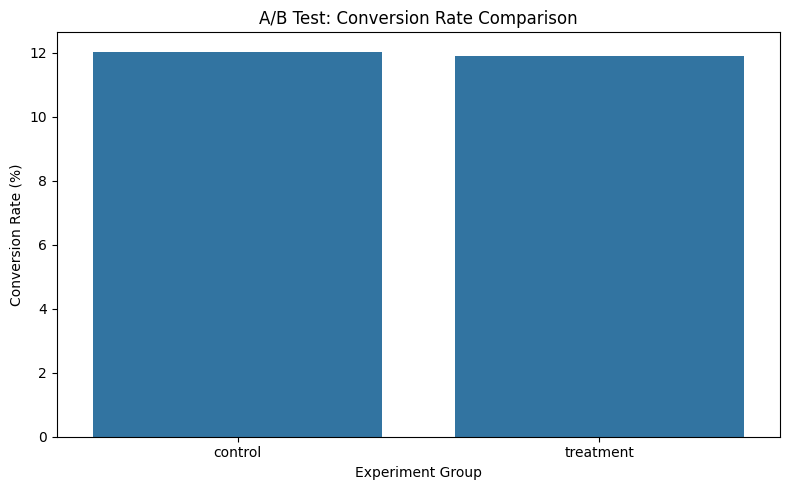

In [11]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=summary.index,
    y=summary['conversion_rate'] * 100
)

plt.title('A/B Test: Conversion Rate Comparison')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()


In [12]:

counts = summary.loc[
    ['control', 'treatment'], 'conversions'
].to_numpy()

sample_sizes = summary.loc[
    ['control', 'treatment'], 'total_users'
].to_numpy()

z_stat, p_value = proportions_ztest(
    counts, sample_sizes, alternative='two-sided'
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")


Z-statistic: 1.2369
P-value: 0.216116
Result: No statistically significant difference.


In [13]:

control_rate = summary.loc['control', 'conversion_rate']
treatment_rate = summary.loc['treatment', 'conversion_rate']

difference = treatment_rate - control_rate
relative_lift = (
    difference / control_rate if control_rate > 0 else np.nan
)

print(f"Absolute conversion lift: {difference:.2%}")
print(f"Relative conversion lift: {relative_lift:.2%}")

if p_value < 0.05 and difference > 0:
    print("Recommendation: Consider treatment after checking experiment quality.")
elif p_value < 0.05 and difference < 0:
    print("Recommendation: Control performs better; investigate before rollout.")
else:
    print("Recommendation: Do not declare a winner yet.")


Absolute conversion lift: -0.15%
Relative conversion lift: -1.23%
Recommendation: Do not declare a winner yet.


In [14]:

# Final results summary

results = pd.DataFrame({
    'Metric': [
        'Total Users',
        'Control Conversion Rate',
        'Treatment Conversion Rate',
        'Absolute Lift (percentage points)',
        'Relative Lift (%)',
        'Z-statistic',
        'P-value',
        'Statistical Significance'
    ],
    'Value': [
        len(df),
        f"{control_rate:.2%}",
        f"{treatment_rate:.2%}",
        f"{(treatment_rate - control_rate) * 100:.2f}",
        f"{relative_lift * 100:.2f}%" if pd.notna(relative_lift) else "N/A",
        f"{z_stat:.4f}",
        f"{p_value:.6f}",
        "Significant" if p_value < 0.05 else "Not significant"
    ]
})

display(results)


,Metric,Value
0,Total Users,294478
1,Control Conversion Rate,12.04%
2,Treatment Conversion Rate,11.89%
3,Absolute Lift (percentage points),-0.15
4,Relative Lift (%),-1.23%
5,Z-statistic,1.2369
6,P-value,0.216116
7,Statistical Significance,Not significant


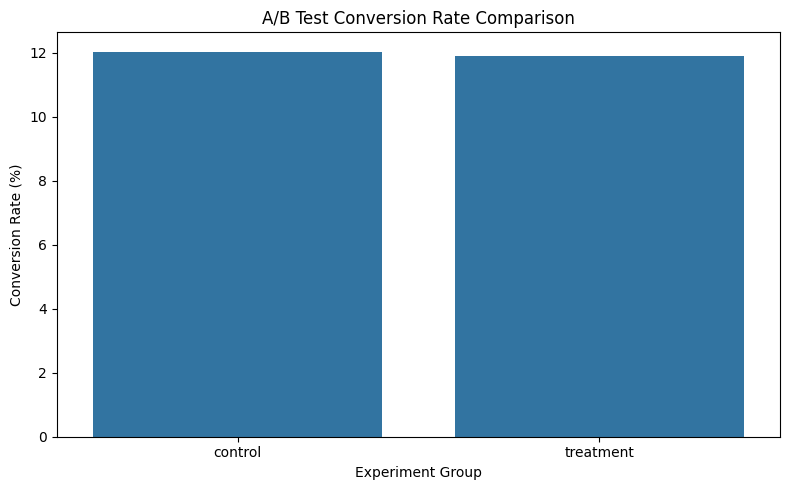

Project results saved successfully!


In [15]:

# Save summary table
summary.to_csv('conversion_summary.csv')

# Save final results
results.to_csv('ab_test_results.csv', index=False)

# Save conversion rate chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=summary.index,
    y=summary['conversion_rate'] * 100
)
plt.title('A/B Test Conversion Rate Comparison')
plt.xlabel('Experiment Group')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.savefig('conversion_rates.png', dpi=300, bbox_inches='tight')
plt.show()

print("Project results saved successfully!")
